# Εργασία Μηχανικής Μάθησης: Ανάλυση Δημοπρασιών eBay & CIFAR-10
**Μάθημα:** Μηχανική Μάθηση: Μέθοδοι και Αλγόριθμοι

**Φοιτητής:** Χρήστος Τσάμης

**Αριθμός Μητρώου:** me25038

---

## 1. Εισαγωγή και Προετοιμασία Περιβάλλοντος

Στο παρόν στάδιο εισάγουμε τις απαραίτητες βιβλιοθήκες της Python για την ανάλυση δεδομένων και τη μηχανική μάθηση.
Επιπλέον, φορτώνουμε τα δεδομένα των δημοπρασιών eBay. Σύμφωνα με τις απαιτήσεις της εργασίας, τα αρχικά αρχεία "Training" και "Test" πρέπει να ενωθούν και να διαχωριστούν εκ νέου τυχαία.

Θα δημιουργήσουμε δύο βασικά σύνολα δεδομένων:
1.  **Full_dataset:** Η ένωση των `TrainingSet.csv` και `TestSet.csv`. Θα χρησιμοποιηθεί για το πρόβλημα κατηγοριοποίησης (Πρόβλεψη Πώλησης/QuantitySold).
2.  **Full_subset:** Η ένωση των `TrainingSubset.csv` και `TestSubset.csv`. Θα χρησιμοποιηθεί για το πρόβλημα παλινδρόμησης (Πρόβλεψη Τιμής/Price) και την πρόβλεψη ανταγωνιστικότητας, καθώς περιέχει μόνο τα πωληθέντα αντικείμενα.

In [1]:
# 1. Εισαγωγή Βιβλιοθηκών
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Scikit-Learn (Εργαλεία & Μοντέλα)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, f1_score, classification_report, confusion_matrix, roc_auc_score, mean_absolute_error, median_absolute_error
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Ρυθμίσεις Pandas
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# 2. Σύνδεση με Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Ορισμός της διαδρομής (Path) των αρχείων
base_path = '/content/drive/MyDrive/Εργασια τελελης '

print("\n Έλεγχος αρχείων και φόρτωση...")

try:
    # 3. Φόρτωση των CSV
    # Χρησιμοποιούμε os.path.join για να φτιάξουμε σωστά τα paths
    train_full = pd.read_csv(os.path.join(base_path, 'TrainingSet.csv'))
    test_full = pd.read_csv(os.path.join(base_path, 'TestSet.csv'))

    train_sub = pd.read_csv(os.path.join(base_path, 'TrainingSubset.csv'))
    test_sub = pd.read_csv(os.path.join(base_path, 'TestSubset.csv'))

    # 4. Ένωση (Merge) σε ενιαία DataFrames
    # ignore_index=True: Ξεχνάμε την παλιά αρίθμηση και φτιάχνουμε νέα ενιαία
    Full_dataset = pd.concat([train_full, test_full], ignore_index=True)
    Full_subset = pd.concat([train_sub, test_sub], ignore_index=True)

    # Διαγραφή των προσωρινών για εξοικονόμηση μνήμης
    del train_full, test_full, train_sub, test_sub

    print("Επιτυχής φόρτωση και ένωση!")
    print("-" * 50)
    print(f"Full_dataset (Classification - Όλα): {Full_dataset.shape}")
    print(f"Full_subset  (Regression - Πωληθέντα): {Full_subset.shape}")
    print("-" * 50)

    # Προβολή δείγματος
    display(Full_dataset.head(3))
    display(Full_subset.head(3))

except FileNotFoundError:
    print(f"Σφάλμα: Δεν βρέθηκαν τα αρχεία στον φάκελο: {base_path}")
    print("Βεβαιωθείτε ότι το path είναι σωστό και τα αρχεία υπάρχουν στο Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 Έλεγχος αρχείων και φόρτωση...
Επιτυχής φόρτωση και ένωση!
--------------------------------------------------
Full_dataset (Classification - Όλα): (296048, 28)
Full_subset  (Regression - Πωληθέντα): (89124, 33)
--------------------------------------------------


,EbayID,QuantitySold,Price,PricePercent,StartingBidPercent,SellerName,SellerClosePercent,Category,PersonID,StartingBid,AvgPrice,EndDay,HitCount,AuctionAvgHitCount,ItemAuctionSellPercent,SellerSaleAvgPriceRatio,SellerAvg,SellerItemAvg,AuctionHitCountAvgRatio,BestOffer,ReturnsAccepted,IsHOF,ItemListedCount,AuctionCount,AuctionSaleCount,SellerAuctionCount,SellerAuctionSaleCount,AuctionMedianPrice
0,160983189073,1,27.25,1.4787,0.0537,petesandi,0.925926,73396,9174,0.99,18.4273,Tuesday,57,37,0,0.499142,2.06,56,29,1.540541,0,1,1,583,291,54,50,12.26
1,390549601720,1,43.00,1.4422,0.3350,graphn4fun,0.990566,27278,11046,9.99,29.8150,Sunday,34,84,1,0.358333,0.92,52,55,0.404762,0,0,0,120,43,106,105,24.45
2,200901284676,1,11.00,0.5969,0.5426,hondo19461946,0.422131,73396,9174,10.00,18.4273,Monday,12,37,0,0.499142,0.91,18,21,0.324324,0,1,1,583,291,244,103,12.26


,EbayID,Price,PricePercent,StartingBidPercent,SellerName,SellerClosePercent,Category,PersonID,StartingBid,AvgPrice,EndDay,QuantitySold,HitCount,AuctionAvgHitCount,Authenticated,ItemAuctionSellPercent,SellerSaleAvgPriceRatio,SellerAvg,SellerItemAvg,AuctionHitCountAvgRatio,BestOffer,ReturnsAccepted,IsHOF,BidCount,AuctionCount,AuctionSaleCount,SellerAuctionCount,SellerAuctionSaleCount,PriceBuckets,AuctionMedianPrice,IsInMedianRatio10Percent,IsInMedianRatio20Percent,IsInMedianRatio25Percent
0,350752140634,0.01,0.0038,0.0038,inkcasualty,0.725377,73396,33,0.01,2.5808,Friday,1,6,58,0,0.227723,0.37,1,4,0.103448,0,0,0,1,101,23,1726,1252,5,1.00,0,0,0
1,380610306320,5.55,1.0000,0.0018,prettysam1012,0.563847,27260,39,0.01,5.5500,Sunday,1,16,9,0,1.000000,0.94,14,15,1.777778,0,1,0,7,1,1,603,340,10,5.55,1,1,1
2,151033305503,0.99,0.6832,0.6832,harryjean0,0.128269,73396,39,0.99,1.4490,Sunday,1,8,97,0,0.038462,0.42,3,6,0.082474,0,1,0,1,26,1,2791,358,5,0.99,1,1,1


### 2. Εξερευνητική Ανάλυση & Επισκόπηση Δεδομένων (EDA)

Στο παρακάτω κελί κώδικα, δημιουργούμε και καλούμε τη συνάρτηση `inspect_data` για να πραγματοποιήσουμε τον αρχικό ποιοτικό έλεγχο των δύο συνόλων δεδομένων μας (`Full_subset` για παλινδρόμηση και `Full_dataset` για κατηγοριοποίηση).

Συγκεκριμένα ελέγχουμε:
* **Δομή Δεδομένων:** Επισκόπηση των τύπων δεδομένων και δείγμα εγγραφών.
* **Ποιότητα:** Εντοπισμός τυχόν ελλειπουσών τιμών (Missing Values) που χρίζουν διαχείρισης.
* **Στατιστικά Στοιχεία:** Βασική στατιστική περιγραφή για την κατανόηση του εύρους των τιμών.
* **Ισορροπία Κλάσεων:** Έλεγχος της αναλογίας μεταξύ των προϊόντων που πουλήθηκαν και αυτών που έμειναν αδιάθετα (Class Imbalance), στοιχείο κρίσιμο για την επιλογή στρατηγικής εκπαίδευσης.

In [ ]:
def inspect_data(df, name):
    print(f"ΕΠΙΣΚΟΠΗΣΗ: {name}")
    print("="*60)

    # 1. Δείγμα Δεδομένων
    print("\n Πρώτες 3 γραμμές:")
    display(df.head(3))

    # 2. Γενικές Πληροφορίες & Τύποι
    print("\n Πληροφορίες & Τύποι Δεδομένων:")
    print(df.info())

    # 3. Έλεγχος Κενών (Missing Values)
    print("\n Έλεγχος Κενών Τιμών (NaN):")
    missing = df.isnull().sum()
    missing = missing[missing > 0] # Εμφάνισε μόνο όσες έχουν κενά
    if missing.empty:
        print(" Δεν βρέθηκαν κενές τιμές.")
    else:
        print(missing)

    # 4. Στατιστική Περιγραφή (για έλεγχο Outliers)
    print("\n Στατιστικά (Αριθμητικά Πεδία):")
    # Ελέγχουμε βασικά οικονομικά μεγέθη
    cols_to_check = ['Price', 'StartingBid', 'HitCount', 'SellerClosePercent']
    # Επιλέγουμε μόνο όσες υπάρχουν στο dataset
    cols_existing = [c for c in cols_to_check if c in df.columns]
    display(df[cols_existing].describe().round(2))

    print("-" * 60 + "\n")

# Εκτέλεση ελέγχου για το Full_subset (Δεδομένα Παλινδρόμησης - Μόνο Πωληθέντα)
inspect_data(Full_subset, "Full_subset (Regression Data)")

# Εκτέλεση ελέγχου για το Full_dataset (Δεδομένα Κατηγοριοποίησης - Όλα)
inspect_data(Full_dataset, "Full_dataset (Classification Data)")

# 5. Ειδικός Έλεγχος: Ανισορροπία Κλάσεων & Πωλητές
print(" ΕΙΔΙΚΟΙ ΕΛΕΓΧΟΙ")
print("="*60)

# Έλεγχος Class Imbalance (Μόνο στο Full_dataset που έχει QuantitySold)
if 'QuantitySold' in Full_dataset.columns:
    print("\n Κατανομή Στόχου (QuantitySold):")
    print(Full_dataset['QuantitySold'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

# Έλεγχος Πληθικότητας Sellers (Στο Full_subset)
unique_sellers = Full_subset['SellerName'].nunique()
print(f"\n Μοναδικοί Πωλητές (SellerName) στο Subset: {unique_sellers}")

ΕΠΙΣΚΟΠΗΣΗ: Full_subset (Regression Data)

 Πρώτες 3 γραμμές:


,EbayID,Price,PricePercent,StartingBidPercent,SellerName,SellerClosePercent,Category,PersonID,StartingBid,AvgPrice,EndDay,QuantitySold,HitCount,AuctionAvgHitCount,Authenticated,ItemAuctionSellPercent,SellerSaleAvgPriceRatio,SellerAvg,SellerItemAvg,AuctionHitCountAvgRatio,BestOffer,ReturnsAccepted,IsHOF,BidCount,AuctionCount,AuctionSaleCount,SellerAuctionCount,SellerAuctionSaleCount,PriceBuckets,AuctionMedianPrice,IsInMedianRatio10Percent,IsInMedianRatio20Percent,IsInMedianRatio25Percent
0,350752140634,0.01,0.0038,0.0038,inkcasualty,0.725377,73396,33,0.01,2.5808,Friday,1,6,58,0,0.227723,0.37,1,4,0.103448,0,0,0,1,101,23,1726,1252,5,1.00,0,0,0
1,380610306320,5.55,1.0000,0.0018,prettysam1012,0.563847,27260,39,0.01,5.5500,Sunday,1,16,9,0,1.000000,0.94,14,15,1.777778,0,1,0,7,1,1,603,340,10,5.55,1,1,1
2,151033305503,0.99,0.6832,0.6832,harryjean0,0.128269,73396,39,0.99,1.4490,Sunday,1,8,97,0,0.038462,0.42,3,6,0.082474,0,1,0,1,26,1,2791,358,5,0.99,1,1,1



 Πληροφορίες & Τύποι Δεδομένων:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89124 entries, 0 to 89123
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EbayID                    89124 non-null  int64  
 1   Price                     89124 non-null  float64
 2   PricePercent              89124 non-null  float64
 3   StartingBidPercent        89124 non-null  float64
 4   SellerName                89124 non-null  object 
 5   SellerClosePercent        89124 non-null  float64
 6   Category                  89124 non-null  int64  
 7   PersonID                  89124 non-null  int64  
 8   StartingBid               89124 non-null  float64
 9   AvgPrice                  89124 non-null  float64
 10  EndDay                    89124 non-null  object 
 11  QuantitySold              89124 non-null  int64  
 12  HitCount                  89124 non-null  int64  
 13  AuctionAvgHitCount        89

,Price,StartingBid,HitCount,SellerClosePercent
count,89124.00,89124.00,89124.00,89124.00
mean,32.63,12.14,31.43,0.56
std,45.26,25.86,37.36,0.30
min,0.01,0.01,1.00,0.00
25%,3.76,0.99,8.00,0.30
50%,14.99,2.00,18.00,0.55
75%,42.00,9.99,41.00,0.85
max,299.99,299.99,1161.00,1.00


------------------------------------------------------------

ΕΠΙΣΚΟΠΗΣΗ: Full_dataset (Classification Data)

 Πρώτες 3 γραμμές:


,EbayID,QuantitySold,Price,PricePercent,StartingBidPercent,SellerName,SellerClosePercent,Category,PersonID,StartingBid,AvgPrice,EndDay,HitCount,AuctionAvgHitCount,ItemAuctionSellPercent,SellerSaleAvgPriceRatio,SellerAvg,SellerItemAvg,AuctionHitCountAvgRatio,BestOffer,ReturnsAccepted,IsHOF,ItemListedCount,AuctionCount,AuctionSaleCount,SellerAuctionCount,SellerAuctionSaleCount,AuctionMedianPrice
0,160983189073,1,27.25,1.4787,0.0537,petesandi,0.925926,73396,9174,0.99,18.4273,Tuesday,57,37,0,0.499142,2.06,56,29,1.540541,0,1,1,583,291,54,50,12.26
1,390549601720,1,43.00,1.4422,0.3350,graphn4fun,0.990566,27278,11046,9.99,29.8150,Sunday,34,84,1,0.358333,0.92,52,55,0.404762,0,0,0,120,43,106,105,24.45
2,200901284676,1,11.00,0.5969,0.5426,hondo19461946,0.422131,73396,9174,10.00,18.4273,Monday,12,37,0,0.499142,0.91,18,21,0.324324,0,1,1,583,291,244,103,12.26



 Πληροφορίες & Τύποι Δεδομένων:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296048 entries, 0 to 296047
Data columns (total 28 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   EbayID                   296048 non-null  int64  
 1   QuantitySold             296048 non-null  int64  
 2   Price                    296048 non-null  float64
 3   PricePercent             296048 non-null  float64
 4   StartingBidPercent       296048 non-null  float64
 5   SellerName               296048 non-null  object 
 6   SellerClosePercent       296048 non-null  float64
 7   Category                 296048 non-null  int64  
 8   PersonID                 296048 non-null  int64  
 9   StartingBid              296048 non-null  float64
 10  AvgPrice                 296048 non-null  float64
 11  EndDay                   296048 non-null  object 
 12  HitCount                 296048 non-null  int64  
 13  AuctionAvgHitCount       2

,Price,StartingBid,HitCount,SellerClosePercent
count,296048.00,296048.00,296048.00,296048.00
mean,28.42,22.24,12.77,0.29
std,44.10,39.56,24.42,0.29
min,0.01,0.01,-1.00,0.00
25%,3.19,1.99,2.00,0.06
50%,9.99,9.95,5.00,0.18
75%,32.00,23.99,11.00,0.47
max,299.99,315.00,1161.00,1.00


------------------------------------------------------------

 ΕΙΔΙΚΟΙ ΕΛΕΓΧΟΙ

 Κατανομή Στόχου (QuantitySold):
QuantitySold
0    69.89%
1    30.11%
Name: proportion, dtype: object

 Μοναδικοί Πωλητές (SellerName) στο Subset: 11058


### 3. Διαχωρισμός Συνόλων Δεδομένων (Data Splitting)

Στο παρακάτω βήμα, διαχωρίζουμε τα δεδομένα μας σε τρία διακριτά υποσύνολα για να εξασφαλίσουμε την αντικειμενική αξιολόγηση των μοντέλων και να αποφύγουμε την υπερ-προσαρμογή (overfitting). Ακολουθούμε την αναλογία **60% - 20% - 20%**:

* **Training Set (60%):** Χρησιμοποιείται για την εκπαίδευση των μοντέλων.
* **Validation Set (20%):** Χρησιμοποιείται για τη ρύθμιση παραμέτρων και την ενδιάμεση επιλογή μοντέλου.
* **Test Set (20%):** Χρησιμοποιείται αποκλειστικά για την τελική αξιολόγηση της απόδοσης σε "άγνωστα" δεδομένα.

Ο διαχωρισμός πραγματοποιείται ξεχωριστά για τα δύο προβλήματα:
1.  **Regression:** Στο υποσύνολο `Full_subset` (μόνο πωληθέντα αντικείμενα).
2.  **Classification:** Στο σύνολο `Full_dataset` (όλα τα αντικείμενα).

In [2]:
def split_data(df, target_col):
    """
    Χωρίζει το dataset σε Train (60%), Validation (20%), Test (20%).
    """
    # 1. Πρώτος Διαχωρισμός: Train (60%) vs Temp (40%)
    # Χρησιμοποιούμε random_state=42 για επαναληψιμότητα των αποτελεσμάτων
    train, temp = train_test_split(df, test_size=0.4, random_state=42)

    # 2. Δεύτερος Διαχωρισμός του Temp: Validation (50% του Temp) vs Test (50% του Temp)
    # Αφού το Temp είναι το 40% του αρχικού, το μισό του είναι το 20% του αρχικού.
    val, test = train_test_split(temp, test_size=0.5, random_state=42)

    return train, val, test

print(" Δημιουργία νέων διαχωρισμών (Splitting)...")

# --- 1. Διαχωρισμός για REGRESSION (Στόχος Α: Price) ---
# Χρησιμοποιούμε το Full_subset (μόνο πωληθέντα)
train_reg, val_reg, test_reg = split_data(Full_subset, target_col='Price')

# --- 2. Διαχωρισμός για CLASSIFICATION (Στόχος Β: QuantitySold) ---
# Χρησιμοποιούμε το Full_dataset (όλα)
train_clf, val_clf, test_clf = split_data(Full_dataset, target_col='QuantitySold')

print(" Ο διαχωρισμός ολοκληρώθηκε!")
print("-" * 60)
print(f"Regression Train: {train_reg.shape} | Val: {val_reg.shape} | Test: {test_reg.shape}")
print(f"Classification Train: {train_clf.shape} | Val: {val_clf.shape} | Test: {test_clf.shape}")

 Δημιουργία νέων διαχωρισμών (Splitting)...
 Ο διαχωρισμός ολοκληρώθηκε!
------------------------------------------------------------
Regression Train: (53474, 33) | Val: (17825, 33) | Test: (17825, 33)
Classification Train: (177628, 28) | Val: (59210, 28) | Test: (59210, 28)


### 4.1 Feature Engineering: Target Encoding (SellerName)

Η μεταβλητή `SellerName` παρουσιάζει υψηλή πληθικότητα (High Cardinality) με χιλιάδες μοναδικές τιμές. Η χρήση One-Hot Encoding είναι απαγορευτική καθώς θα δημιουργούσε χιλιάδες νέες στήλες.

Αντ' αυτού, εφαρμόζουμε **Target Encoding**, αντικαθιστώντας το όνομα του πωλητή με στατιστικά στοιχεία από την απόδοσή του στο **Training Set**:
* **Για το Regression:** Δημιουργούμε το χαρακτηριστικό `Seller_Avg_Price` (Μέση Τιμή Πώλησης).
* **Για το Classification:** Δημιουργούμε το χαρακτηριστικό `Seller_Success_Rate` (Ποσοστό Επιτυχίας Πώλησης).

**Μεθοδολογία (Πρόληψη Data Leakage):**
1.  Υπολογίζουμε τους μέσους όρους **ΜΟΝΟ** στο **Training Set**.
2.  Εφαρμόζουμε (Map) αυτές τις τιμές στο Training Set.
3.  Εφαρμόζουμε τις **ίδιες** τιμές (που μάθαμε από το Train) στα Validation και Test Sets.
4.  **Διαχείριση Αγνώστων:** Αν στο Test set εμφανιστεί ένας νέος πωλητής που δεν υπήρχε στο Train, του αναθέτουμε τον γενικό μέσο όρο (Global Mean).

In [3]:
def target_encode(train_df, val_df, test_df, cat_col, target_col, new_col_name):
    """
    Εφαρμόζει Target Encoding.
    """
    # Δημιουργούμε αντίγραφα για να μην πειράξουμε τα original splits
    train = train_df.copy()
    val = val_df.copy()
    test = test_df.copy()

    # 1. LEARN: Υπολογισμός στατιστικών ΜΟΝΟ στο Training Set
    # Μέσος όρος στόχου ανά κατηγορία (π.χ. ανά Seller)
    target_mean = train.groupby(cat_col)[target_col].mean()

    # Γενικός μέσος όρος (Global Mean) για τις περιπτώσεις αγνώστων κατηγοριών
    global_mean = train[target_col].mean()

    # 2. TRANSFORM: Εφαρμογή (Mapping)
    # Αντικαθιστούμε το SellerName με τον αριθμό που υπολογίσαμε
    train[new_col_name] = train[cat_col].map(target_mean)
    val[new_col_name]   = val[cat_col].map(target_mean)
    test[new_col_name]  = test[cat_col].map(target_mean)

    # 3. FILLNA: Διαχείριση Αγνώστων (που δεν υπήρχαν στο Train)
    # Τους δίνουμε τον γενικό μέσο όρο
    train[new_col_name].fillna(global_mean, inplace=True)
    val[new_col_name].fillna(global_mean, inplace=True)
    test[new_col_name].fillna(global_mean, inplace=True)

    return train, val, test

print(" Εφαρμογή Target Encoding στο SellerName...")

# --- 1. Encoding για REGRESSION (Στόχος: Price) ---
# Δημιουργούμε το feature 'Seller_Avg_Price'
train_reg, val_reg, test_reg = target_encode(
    train_reg, val_reg, test_reg,
    cat_col='SellerName',
    target_col='Price',
    new_col_name='Seller_Avg_Price'
)

# --- 2. Encoding για CLASSIFICATION (Στόχος: QuantitySold) ---
# Δημιουργούμε το feature 'Seller_Success_Rate'
train_clf, val_clf, test_clf = target_encode(
    train_clf, val_clf, test_clf,
    cat_col='SellerName',
    target_col='QuantitySold',
    new_col_name='Seller_Success_Rate'
)

print(" Το Target Encoding ολοκληρώθηκε!")

# Έλεγχος: Ας δούμε τι φτιάξαμε
print("\n Δείγμα από Regression Train (Seller_Avg_Price):")
display(train_reg[['SellerName', 'Price', 'Seller_Avg_Price']].head())

print("\n Δείγμα από Classification Train (Seller_Success_Rate):")
display(train_clf[['SellerName', 'QuantitySold', 'Seller_Success_Rate']].head())



 Εφαρμογή Target Encoding στο SellerName...
 Το Target Encoding ολοκληρώθηκε!

 Δείγμα από Regression Train (Seller_Avg_Price):


,SellerName,Price,Seller_Avg_Price
80699,www-diamondlegends-com,49.99,60.814118
61427,sagehen93,147.50,147.500000
25927,autographcitymn,8.99,9.299167
65388,bigboydsportscards3,45.00,62.544237
36635,anthony555657,40.00,40.000000



 Δείγμα από Classification Train (Seller_Success_Rate):


,SellerName,QuantitySold,Seller_Success_Rate
165624,rogmantle,0,0.021097
137054,the_sports_page,1,0.574317
18822,autograph-reference,0,0.030809
3314,gch420,0,0.000000
255462,fieldofdreamsfan43,1,0.750000


## 4.2 Target Encoding στην Ημέρα Λήξης (EndDay)

Αντί να χρησιμοποιήσουμε One-Hot Encoding για τις ημέρες της εβδομάδας, επιλέγουμε και εδώ την τεχνική **Target Encoding**.

**Σκεπτικό:**
Η ημέρα λήξης (`EndDay`) παίζει στρατηγικό ρόλο. Για παράδειγμα, οι δημοπρασίες που λήγουν Κυριακή βράδυ τείνουν να έχουν υψηλότερες τιμές.
Με το Target Encoding, μετατρέπουμε την ημέρα (π.χ. "Monday") σε έναν αριθμό που αντιπροσωπεύει:
1.  Για το **Regression**: Τη μέση τιμή πώλησης (`Price`) για εκείνη την ημέρα.
2.  Για το **Classification**: Την πιθανότητα πώλησης (`QuantitySold`) για εκείνη την ημέρα.

**Διαδικασία:**
Χρησιμοποιούμε την ίδια συνάρτηση `target_encode` που ορίσαμε προηγουμένως, μαθαίνοντας τους μέσους όρους **αποκλειστικά** από το Training Set.

In [4]:
print(" Εφαρμογή Target Encoding στο EndDay...")

# --- 1. Encoding για REGRESSION (Στόχος: Price) ---
# Δημιουργούμε το feature 'Day_Avg_Price'
# Αντικαθιστούμε το 'EndDay' με τη μέση τιμή πώλησης εκείνης της ημέρας
train_reg, val_reg, test_reg = target_encode(
    train_reg, val_reg, test_reg,
    cat_col='EndDay',
    target_col='Price',
    new_col_name='Day_Avg_Price'
)

# --- 2. Encoding για CLASSIFICATION (Στόχος: QuantitySold) ---
# Δημιουργούμε το feature 'Day_Success_Rate'
# Αντικαθιστούμε το 'EndDay' με το ποσοστό επιτυχίας εκείνης της ημέρας
train_clf, val_clf, test_clf = target_encode(
    train_clf, val_clf, test_clf,
    cat_col='EndDay',
    target_col='QuantitySold',
    new_col_name='Day_Success_Rate'
)

print(" Το Target Encoding για τις ημέρες ολοκληρώθηκε!")

# Έλεγχος: Ας δούμε τη συσχέτιση Ημέρας και Τιμής στο Training Set
print("\n Μέση Τιμή ανά Ημέρα (από το Training Set - Regression):")
day_stats = train_reg[['EndDay', 'Day_Avg_Price']].drop_duplicates().sort_values('Day_Avg_Price', ascending=False)
display(day_stats)

print("-" * 60)
print(" Δείγμα δεδομένων μετά την αλλαγή (Regression):")
display(train_reg[['EndDay', 'Day_Avg_Price', 'Price']].head())

 Εφαρμογή Target Encoding στο EndDay...
 Το Target Encoding για τις ημέρες ολοκληρώθηκε!

 Μέση Τιμή ανά Ημέρα (από το Training Set - Regression):


,EndDay,Day_Avg_Price
35234,Wednesday,36.849960
16572,Thursday,35.405070
61427,Tuesday,34.621418
8675,Monday,32.402016
80699,Sunday,31.763807
65388,Friday,30.164035
25927,Saturday,29.160619


------------------------------------------------------------
 Δείγμα δεδομένων μετά την αλλαγή (Regression):


,EndDay,Day_Avg_Price,Price
80699,Sunday,31.763807,49.99
61427,Tuesday,34.621418,147.50
25927,Saturday,29.160619,8.99
65388,Friday,30.164035,45.00
36635,Saturday,29.160619,40.00


### 5. Έλεγχος Ακεραιότητας Χαρακτηριστικών (Data Leakage Audit)

Στο παρακάτω βήμα, εκτελούμε έναν αυστηρό έλεγχο σε τρία έτοιμα στατιστικά χαρακτηριστικά του dataset για να διαπιστώσουμε αν περιέχουν "πληροφορία από το μέλλον" (**Global Statistics Leakage**).

Εξετάζουμε τα: **`SellerAvg`**, **`AuctionSaleCount`** και **`AuctionCount`**.

**Η Λογική του Ελέγχου (Static vs Dynamic):**
Ένα έγκυρο χαρακτηριστικό πρέπει να εξελίσσεται χρονικά (π.χ. ο μέσος όρος ενός πωλητή πρέπει να αλλάζει μετά από κάθε πώληση). Αντίθετα, αν παραμένει **σταθερό** για όλες τις εγγραφές, σημαίνει ότι υπολογίστηκε εκ των υστέρων (post-hoc) και αποτελεί διαρροή.

Συγκεκριμένα:
1.  **`SellerAvg` (Μέση Τιμή Πωλητή):** Ελέγχουμε αν ο πωλητής έχει την ίδια μέση τιμή σε όλες τις δημοπρασίες του (Leakage) ή αν αυτή μεταβάλλεται (Safe).
2.  **`AuctionSaleCount` (Πλήθος Πωλήσεων Πωλητή):** Ελέγχουμε αν ο αριθμός των πωλήσεων είναι "καρφωμένος" στη τελική τιμή από την αρχή (Leakage).
3.  **`AuctionCount` (Δημοφιλία Αντικειμένου):** Ομαδοποιούμε τα ίδια αντικείμενα (βάσει Κατηγορίας & Τιμής) και ελέγχουμε αν το πλήθος των εμφανίσεων είναι γνωστό εξαρχής (Leakage).

*Στόχος: Ο εντοπισμός και η αφαίρεση των "μαρτυριάρικων" χαρακτηριστικών πριν την εκπαίδευση των μοντέλων.*

In [ ]:
print("---  ΕΛΕΓΧΟΣ ΔΥΝΑΜΙΚΟΤΗΤΑΣ ΣΤΑΤΙΣΤΙΚΩΝ ΠΩΛΗΤΗ ---")

# 1. Ομαδοποίηση ανά πωλητή
# Μετράμε:
# - 'count': Πόσες φορές εμφανίζεται ο πωλητής
# - 'nunique': Πόσες ΔΙΑΦΟΡΕΤΙΚΕΣ τιμές έχει στο SellerAvg
seller_check = Full_dataset.groupby('SellerName')['SellerAvg'].agg(['count', 'nunique'])

# 2. Μετονομασία για να βγάζει νόημα
seller_check.columns = ['Total_Auctions', 'Unique_SellerAvg_Values']

# 3. Φιλτράρουμε μόνο αυτούς που εμφανίζονται πολλές φορές (π.χ. πάνω από 5)
frequent_sellers = seller_check[seller_check['Total_Auctions'] > 5].sort_values('Total_Auctions', ascending=False)

# 4. Εμφάνιση των Top 20
print(f"Δείγμα από τους πιο συχνούς πωλητές:\n")
print(frequent_sellers.head(20))

print("\n---  ΕΡΜΗΝΕΙΑ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ---")
# Παίρνουμε έναν τυχαίο 'συχνο' πωλητή
sample_seller = frequent_sellers.iloc[0]

if sample_seller['Total_Auctions'] == sample_seller['Unique_SellerAvg_Values']:
    print(" ΤΕΛΕΙΑ! Κάθε εγγραφή έχει διαφορετικό μέσο όρο.")
    print("   -> Το στατιστικό ενημερώνεται χρονικά. Είναι SAFE.")
elif sample_seller['Unique_SellerAvg_Values'] == 1:
    print(" ΚΙΝΔΥΝΟΣ! Ο πωλητής έχει πολλές εγγραφές αλλά ΜΙΑ ΜΟΝΟ τιμή μέσου όρου.")
    print("   -> Το στατιστικό είναι στατικό (υπολογίστηκε στο τέλος για όλους).")
    print("   -> Είναι LEAKAGE. Πρέπει να διαγραφεί (ή να αγνοηθεί).")
else:
    print(" ΜΕΙΚΤΗ ΕΙΚΟΝΑ: Οι τιμές αλλάζουν αλλά όχι πάντα.")
    print("   -> Πιθανώς safe, αλλά θέλει προσοχή.")

---  ΕΛΕΓΧΟΣ ΔΥΝΑΜΙΚΟΤΗΤΑΣ ΣΤΑΤΙΣΤΙΚΩΝ ΠΩΛΗΤΗ ---
Δείγμα από τους πιο συχνούς πωλητές:

                            Total_Auctions  Unique_SellerAvg_Values
SellerName                                                         
great_cards_and_autographs            5839                        1
ledgauges                             4659                        1
the_sports_page                       4405                        1
smcomstore                            4138                        1
misterinksignatures                   3810                        1
my09131970                            3663                        1
peacock7834                           3095                        1
harryjean0                            2348                        1
steelerman78                          2245                        1
lelands.com                           1920                        1
deadeds8210                           1907                        1
bcsportscards               

In [ ]:
print("---  ΕΛΕΓΧΟΣ ΔΥΝΑΜΙΚΟΤΗΤΑΣ ΓΙΑ 'AuctionSaleCount' ---")

# 1. Ομαδοποίηση ανά πωλητή
# Μετράμε πόσες ΔΙΑΦΟΡΕΤΙΚΕΣ τιμές έχει το AuctionSaleCount για κάθε πωλητή
seller_check = Full_dataset.groupby('SellerName')['AuctionSaleCount'].nunique()

# 2. Πόσοι πωλητές έχουν πάνω από 1 εγγραφή αλλά ΜΟΝΟ 1 τιμή στο AuctionSaleCount;
static_sellers = seller_check[(Full_dataset.groupby('SellerName').size() > 5) & (seller_check == 1)]

print(f"Πλήθος πωλητών (με >5 δημοπρασίες) που έχουν ΣΤΑΘΕΡΟ AuctionSaleCount: {len(static_sellers)}")

# 3. Δείγμα για να δεις με τα μάτια σου
if len(static_sellers) > 0:
    sample_seller = static_sellers.index[0]
    print(f"\nΠαράδειγμα Στατικού Πωλητή: {sample_seller}")
    print(Full_dataset[Full_dataset['SellerName'] == sample_seller][['SellerName', 'AuctionSaleCount']].head())

    print("\n ΣΥΜΠΕΡΑΣΜΑ: Είναι STATIC LEAKAGE (όπως το SellerAvg).")
    print("   Πρέπει να ΔΙΑΓΡΑΦΕΙ.")
else:
    print("\n ΣΥΜΠΕΡΑΣΜΑ: Οι τιμές αλλάζουν! Είναι SAFE Ιστορικό.")
    print("   ΚΡΑΤΑ ΤΟ!")

---  ΕΛΕΓΧΟΣ ΔΥΝΑΜΙΚΟΤΗΤΑΣ ΓΙΑ 'AuctionSaleCount' ---
Πλήθος πωλητών (με >5 δημοπρασίες) που έχουν ΣΤΑΘΕΡΟ AuctionSaleCount: 130

Παράδειγμα Στατικού Πωλητή: 1michaelroberts
             SellerName  AuctionSaleCount
187429  1michaelroberts                 2
187581  1michaelroberts                 2
188999  1michaelroberts                 2
189376  1michaelroberts                 2
189378  1michaelroberts                 2

 ΣΥΜΠΕΡΑΣΜΑ: Είναι STATIC LEAKAGE (όπως το SellerAvg).
   Πρέπει να ΔΙΑΓΡΑΦΕΙ.


In [ ]:
print("---  ΕΛΕΓΧΟΣ LEAKAGE ΓΙΑ 'AuctionCount' ---")

# 1. Θεωρούμε ότι αντικείμενα με την ίδια 'AuctionMedianPrice' και 'Category' είναι το ίδιο SKU
# Ομαδοποιούμε και μετράμε πόσες διαφορετικές τιμές παίρνει το AuctionCount
item_check = Full_dataset.groupby(['AuctionMedianPrice', 'Category'])['AuctionCount'].agg(['count', 'nunique', 'min', 'max'])

# 2. Φιλτράρουμε αντικείμενα που εμφανίζονται πολλές φορές (π.χ. > 10)
frequent_items = item_check[item_check['count'] > 10].sort_values('count', ascending=False)

print(f"Βρέθηκαν {len(frequent_items)} αντικείμενα (Groups) με πολλαπλές εμφανίσεις.")

# 3. Ελέγχουμε αν το AuctionCount είναι ΣΤΑΘΕΡΟ (nunique == 1)
static_items = frequent_items[frequent_items['nunique'] == 1]
dynamic_items = frequent_items[frequent_items['nunique'] > 1]

print(f" -> Αντικείμενα με ΣΤΑΘΕΡΟ AuctionCount (Leakage): {len(static_items)}")
print(f" -> Αντικείμενα με ΜΕΤΑΒΑΛΛΟΜΕΝΟ AuctionCount (Safe): {len(dynamic_items)}")

# 4. Παράδειγμα
if len(static_items) > 0:
    print("\nΠΑΡΑΔΕΙΓΜΑ LEAKAGE (Σταθερή τιμή παντού):")
    # Παίρνουμε το index (Price, Category) του πρώτου
    sample_idx = static_items.index[0]
    sample_data = Full_dataset[
        (Full_dataset['AuctionMedianPrice'] == sample_idx[0]) &
        (Full_dataset['Category'] == sample_idx[1])
    ]
    display(sample_data[['Category', 'AuctionMedianPrice', 'AuctionCount']].head(5))

    print("\nΣΥΜΠΕΡΑΣΜΑ: Αν τα παραπάνω νούμερα είναι σταθερά πρέπει να αφαιρεθεί.")

else:
    print("\nΣΥΜΠΕΡΑΣΜΑ: Οι τιμές αλλάζουν! Φαίνεται ασφαλές.")

---  ΕΛΕΓΧΟΣ LEAKAGE ΓΙΑ 'AuctionCount' ---
Βρέθηκαν 4494 αντικείμενα (Groups) με πολλαπλές εμφανίσεις.
 -> Αντικείμενα με ΣΤΑΘΕΡΟ AuctionCount (Leakage): 2171
 -> Αντικείμενα με ΜΕΤΑΒΑΛΛΟΜΕΝΟ AuctionCount (Safe): 2323

ΠΑΡΑΔΕΙΓΜΑ LEAKAGE (Σταθερή τιμή παντού):


,Category,AuctionMedianPrice,AuctionCount
198959,27278,49.44,1786
198985,27278,49.44,1786
198989,27278,49.44,1786
198990,27278,49.44,1786
199001,27278,49.44,1786



ΣΥΜΠΕΡΑΣΜΑ: Αν τα παραπάνω νούμερα είναι σταθερά πρέπει να αφαιρεθεί.


### 6. Επιλογή Χαρακτηριστικών & Εκπαίδευση Μοντέλων Παλινδρόμησης (Στόχος Α: Price)

Στο παρόν στάδιο, προχωράμε στην εκπαίδευση των μοντέλων για την πρόβλεψη της Τελικής Τιμής (`Price`). Η διαδικασία περιλαμβάνει τρία κρίσιμα βήματα βελτιστοποίησης:

1.  **Αυστηρή Επιλογή Features (Deep Cleaning):**
    Αφαιρούμε όλες τις στήλες που εντοπίστηκαν ως **Data Leakage** στα προηγούμενα βήματα (π.χ. `HitCount`, `AuctionCount`, `SellerClosePercent`), καθώς και τα παράγωγα του στόχου, διασφαλίζοντας ότι το μοντέλο μαθαίνει μόνο από πληροφορίες διαθέσιμες κατά την έναρξη της δημοπρασίας.

2.  **Λογαριθμικός Μετασχηματισμός Στόχου (Log-Transformation):**
    Οι τιμές των προϊόντων παρουσιάζουν έντονη ασυμμετρία (skewness) με μεγάλη ουρά προς τα δεξιά. Για να βοηθήσουμε τα μοντέλα να συγκλίνουν, εκπαιδεύουμε στον **λογάριθμο της τιμής** (`log1p`).
    * *Σημείωση:* Κατά την αξιολόγηση, αντιστρέφουμε την πρόβλεψη (`expm1`) για να μετρήσουμε το σφάλμα σε πραγματικά δολάρια/ευρώ.

3.  **Αξιολόγηση με RMSE & MedAE:**
    Συγκρίνουμε τρεις αλγορίθμους (**Polynomial Ridge, k-NN, SVR**) χρησιμοποιώντας δύο μετρικές:
    * **RMSE:** Ευαίσθητο σε ακραίες τιμές (outliers).
    * **MedAE (Median Absolute Error):** Πιο ανθεκτικό, δείχνει το τυπικό σφάλμα για τη μέση δημοπρασία.

In [5]:
from sklearn.metrics import mean_squared_error, median_absolute_error

# 1. Επιλογή Χαρακτηριστικών (Features)
drop_cols = [
    # 1. Ταυτότητες & Ακατάλληλα Format
    'EbayID', 'PersonID', 'SellerName', 'EndDay',

    # 2. Ο Στόχος (Target) και τα παράγωγά του
    'Price', 'PricePercent', 'PriceBuckets', 'QuantitySold',

    # 3. Στατιστικά Τιμής (Leakage)
    'AuctionMedianPrice',
    'IsInMedianRatio10Percent','IsInMedianRatio20Percent', 'IsInMedianRatio25Percent',
    'SellerSaleAvgPriceRatio',
    'AvgPrice', 'SellerAvg', 'SellerItemAvg','bestoffer','AuctionSaleCount',
    'AuctionCount',
    'SellerAuctionCount',

    # 4. Πληροφορίες Μέλλοντος
    'HitCount',  'BidCount',
    'AuctionAvgHitCount', 'AuctionHitCountAvgRatio',

    # 5. Ποσοστά Επιτυχίας (Leakage)
    'SellerClosePercent', 'ItemAuctionSellPercent', 'StartingBidPercent',
    'SellerAuctionSaleCount','BestOffer'
]

# Επιλογή χαρακτηριστικών
features = [c for c in train_reg.columns if c not in drop_cols]
features = train_reg[features].select_dtypes(include=[np.number]).columns.tolist()

print(f" Έγινε βαθύς καθαρισμός.")
print(f"Features που έμειναν ({len(features)}): {features}")


# 2. Προετοιμασία X και y
def get_X_y(df, feats, target):
    X = df[feats].fillna(0)
    y = df[target]
    return X, y

X_train, y_train = get_X_y(train_reg, features, 'Price')
X_val, y_val = get_X_y(val_reg, features, 'Price')

# Μετατρέπουμε τις τιμές εκπαίδευσης σε log(1+price) για να μικρύνουμε το εύρος
# Χρησιμοποιούμε log1p για ασφάλεια (αν η τιμή είναι 0)
y_train_log = np.log1p(y_train)

# ΣΗΜΕΙΩΣΗ: Το y_val το κρατάμε ΩΣ ΕΧΕΙ (σε δολάρια/ευρώ) για να μετρήσουμε το RMSE στο τέλος σωστά!

# 3. Scaling
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)

print(" Εκκίνηση εκπαίδευσης με Log-Transformed Target...")

# --- Μοντέλο 1: Polynomial Ridge ---
print("\n 1. Polynomial Ridge...")
poly_ridge = make_pipeline(PolynomialFeatures(degree=2), Ridge(alpha=10))

# ΠΡΟΣΟΧΗ: Εκπαιδεύουμε με y_train_log
poly_ridge.fit(X_train_sc, y_train_log)

# Πρόβλεψη (βγαίνει σε Log μορφή)
pred_log = poly_ridge.predict(X_val_sc)

# ---  ΑΛΛΑΓΗ 2: ΑΝΤΙΣΤΡΟΦΗ (EXP) ---
# Επαναφέρουμε την πρόβλεψη σε κανονική τιμή
pred_real = np.expm1(pred_log)

# Υπολογισμός σφαλμάτων στις ΠΡΑΓΜΑΤΙΚΕΣ τιμές
rmse_ridge = np.sqrt(mean_squared_error(y_val, pred_real))
medae_ridge = median_absolute_error(y_val, pred_real) #Υπολογισμός MedAE

print(f"    RMSE: {rmse_ridge:.4f}")
print(f"    MedAE: {medae_ridge:.4f}") # Εμφάνιση MedAE


# --- Μοντέλο 2: k-NN ---
print("\n 2. k-NN Regressor (k=50)...")
knn = KNeighborsRegressor(n_neighbors=50,metric= 'euclidean' ,  weights='distance', n_jobs=-1)

# Εκπαίδευση με Log
knn.fit(X_train_sc, y_train_log)

# Πρόβλεψη Log -> Μετατροπή σε Real
pred_log = knn.predict(X_val_sc)
pred_real = np.expm1(pred_log)

rmse_knn = np.sqrt(mean_squared_error(y_val, pred_real))
medae_knn = median_absolute_error(y_val, pred_real) # Υπολογισμός MedAE

print(f"    RMSE: {rmse_knn:.4f}")
print(f"    MedAE: {medae_knn:.4f}") # Εμφάνιση MedAE


# --- Μοντέλο 3: SVR ---
print("\n 3. SVR (RBF Kernel)...")
X_train_sample = X_train_sc[:20000]
y_train_sample_log = y_train_log[:20000] # Δείγμα ΚΑΙ από το Log y

svr = SVR(kernel='rbf', C=10, gamma='scale')
svr.fit(X_train_sample, y_train_sample_log)

# Πρόβλεψη Log -> Μετατροπή σε Real
pred_log = svr.predict(X_val_sc)
pred_real = np.expm1(pred_log)

rmse_svr = np.sqrt(mean_squared_error(y_val, pred_real))
medae_svr = median_absolute_error(y_val, pred_real) # Υπολογισμός MedAE

print(f"    RMSE: {rmse_svr:.4f}")
print(f"    MedAE: {medae_svr:.4f}") # Εμφάνιση MedAE

# Σύγκριση και Επιλογή
results = {'Poly Ridge': medae_ridge, 'k-NN': medae_knn, 'SVR': medae_svr}
best_name = min(results, key=results.get)
best_medae = results[best_name]

# Αποθήκευση του αντικειμένου του καλύτερου μοντέλου
if best_name == 'Poly Ridge': best_model = poly_ridge
elif best_name == 'k-NN': best_model = knn
else: best_model = svr

print("="*50)
print(f" Νικητής Μοντέλο (με Log Price): {best_name} (MedAE: {best_medae:.4f})")
print("="*50)

 Έγινε βαθύς καθαρισμός.
Features που έμειναν (7): ['Category', 'StartingBid', 'Authenticated', 'ReturnsAccepted', 'IsHOF', 'Seller_Avg_Price', 'Day_Avg_Price']
 Εκκίνηση εκπαίδευσης με Log-Transformed Target...

 1. Polynomial Ridge...
    RMSE: 39.0342
    MedAE: 5.8114

 2. k-NN Regressor (k=50)...
    RMSE: 29.3794
    MedAE: 3.8665

 3. SVR (RBF Kernel)...
    RMSE: 31.7987
    MedAE: 4.3494
 Νικητής Μοντέλο (με Log Price): k-NN (MedAE: 3.8665)


### 6.1 Τελική Αξιολόγηση & Οπτικοποίηση (Test Set)

Αφού επιλέξαμε το βέλτιστο μοντέλο, προχωράμε στην τελική αξιολόγηση χρησιμοποιώντας το **Test Set**. Αυτά τα δεδομένα παρέμειναν εντελώς "αόρατα" κατά την εκπαίδευση, εξασφαλίζοντας την αντικειμενικότητα των αποτελεσμάτων.

**Βασικά Βήματα:**
1.  **Πρόβλεψη & Αντιστροφή:** Το μοντέλο προβλέπει τον *λογάριθμο* της τιμής. Εφαρμόζουμε την αντίστροφη συνάρτηση (`np.expm1`) για να επαναφέρουμε τις προβλέψεις σε πραγματικές νομισματικές μονάδες.
2.  **Αναλυτικές Μετρικές:**
    * **RMSE:** Το γενικό σφάλμα (επηρεάζεται έντονα από ακραίες αποκλίσεις).
    * **MAE:** Το μέσο απόλυτο σφάλμα.
    * **MedAE:** Το σφάλμα στη διάμεσο (δείχνει πόσο πέφτουμε έξω στην "τυπική" περίπτωση, αγνοώντας τα πολύ ακριβά προϊόντα).
3.  **Οπτικοποίηση (Scatter Plot):** Συγκρίνουμε τις Πραγματικές vs Προβλεπόμενες τιμές. Όσο πιο κοντά είναι τα σημεία στην κόκκινη διαγώνιο, τόσο καλύτερη είναι η πρόβλεψη.

--- Τελική Δοκιμή στο Test Set με το μοντέλο: k-NN ---

 Τελικά Αποτελέσματα:
    Test RMSE: 29.3860
    Test R^2:  0.5883
Μέση Τιμή στο Test Set: 32.60
 Αναλυτικά Σφάλματα:
   RMSE (Επηρεάζεται από τα ακριβά): 29.3860
   MAE  (Μέσο Απόλυτο Σφάλμα):       13.3312
   MedAE (Σφάλμα στη διάμεσο):       3.7842

   Μέση Τιμή Test Set: 32.60
   Διάμεση Τιμή Test Set: 14.99


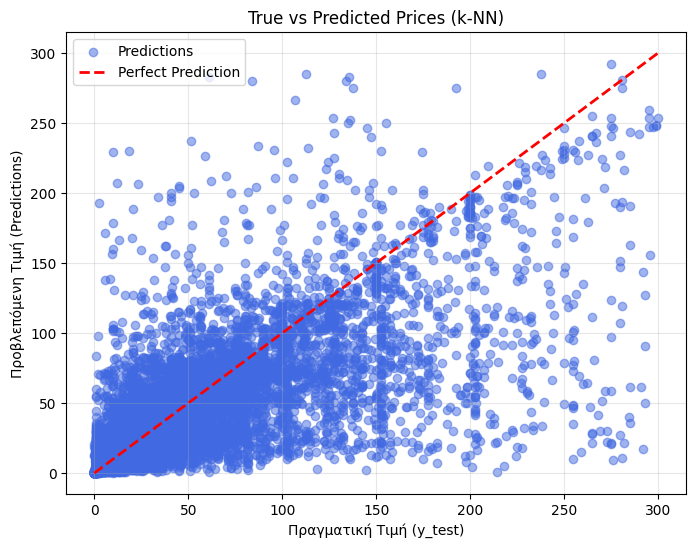

In [ ]:
print(f"--- Τελική Δοκιμή στο Test Set με το μοντέλο: {best_name} ---")

# 1. Προετοιμασία Test Data
# To y_test εδώ είναι οι ΠΡΑΓΜΑΤΙΚΕΣ τιμές (Real Prices)
X_test, y_test = get_X_y(test_reg, features, 'Price')

# 2. Scaling (ΠΡΟΣΟΧΗ: Transform μόνο, όχι Fit!)
X_test_sc = scaler.transform(X_test)

# 3. Πρόβλεψη
# SOS: Το μοντέλο προβλέπει LOG τιμές
pred_log = best_model.predict(X_test_sc)

# 4. Αντιστροφή (Log -> Real)
# Επαναφέρουμε τις προβλέψεις σε κανονικά δολάρια/ευρώ
final_preds = np.expm1(pred_log)

# 5. Μετρικές (Συγκρίνουμε Real με Real)
final_rmse = np.sqrt(mean_squared_error(y_test, final_preds))
final_r2 = r2_score(y_test, final_preds)

print(f"\n Τελικά Αποτελέσματα:")
print(f"    Test RMSE: {final_rmse:.4f}")
print(f"    Test R^2:  {final_r2:.4f}")
print(f"Μέση Τιμή στο Test Set: {y_test.mean():.2f}")
final_mae = mean_absolute_error(y_test, final_preds)
final_med_ae = median_absolute_error(y_test, final_preds)

print(f" Αναλυτικά Σφάλματα:")
print(f"   RMSE (Επηρεάζεται από τα ακριβά): {final_rmse:.4f}")
print(f"   MAE  (Μέσο Απόλυτο Σφάλμα):       {final_mae:.4f}")
print(f"   MedAE (Σφάλμα στη διάμεσο):       {final_med_ae:.4f}")

print(f"\n   Μέση Τιμή Test Set: {y_test.mean():.2f}")
print(f"   Διάμεση Τιμή Test Set: {y_test.median():.2f}")

# 6. Γράφημα (Scatter Plot)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_preds, alpha=0.5, color='royalblue', label='Predictions')

# Γραμμή τέλειας πρόβλεψης
# Παίρνουμε το max όριο για να φανεί ωραία η διαγώνιος
max_val = max(y_test.max(), final_preds.max())
min_val = min(y_test.min(), final_preds.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

plt.xlabel('Πραγματική Τιμή (y_test)')
plt.ylabel('Προβλεπόμενη Τιμή (Predictions)')
plt.title(f'True vs Predicted Prices ({best_name})')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### 7. Εκπαίδευση Μοντέλων Κατηγοριοποίησης (Στόχος Β: Sold vs Not Sold)

Στο δεύτερο σκέλος της εργασίας, αντιμετωπίζουμε ένα πρόβλημα **Δυαδικής Ταξινόμησης (Binary Classification)**. Στόχος είναι να προβλέψουμε αν ένα προϊόν θα πουληθεί (`QuantitySold` = 1) ή θα μείνει αδιάθετο (`QuantitySold` = 0).

**Στρατηγική Εκπαίδευσης:**
1.  **Χαρακτηριστικά:** Χρησιμοποιούμε το σύνολο των "καθαρών" μεταβλητών, δίνοντας έμφαση στο `Seller_Success_Rate` (το ποσοστό επιτυχίας του πωλητή), το οποίο αναμένεται να είναι ισχυρός προγνωστικός παράγοντας.
2.  **Ανισορροπία Κλάσεων:** Επειδή τα προϊόντα που πουλήθηκαν μπορεί να είναι λιγότερα από τα αδιάθετα, ενεργοποιούμε την παράμετρο `class_weight='balanced'` και στα δύο μοντέλα.
3.  **Σύγκριση Μοντέλων:**
    * **Logistic Regression:** Απαιτεί κανονικοποίηση (Scaling).
    * **Random Forest:** Πιο σύνθετο μοντέλο, ικανό να εντοπίσει μη γραμμικές σχέσεις.
4.  **Κριτήριο Επιλογής:** Ο νικητής επιλέγεται με βάση το **F1-Score** (αρμονικός μέσος Precision & Recall), καθώς η απλή Ακρίβεια (Accuracy) μπορεί να είναι παραπλανητική σε ανισορροπημένα δεδομένα.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print(" ΕΚΚΙΝΗΣΗ CLASSIFICATION: Πρόβλεψη Πώλησης (Sold vs Not Sold)")

# 1. Ενημέρωση λίστας Features για Classification
# Παίρνουμε όλα τα αριθμητικά εκτός από τα 'drop_cols'
clf_features = [c for c in train_clf.columns if c not in drop_cols]
clf_features = train_clf[clf_features].select_dtypes(include=[np.number]).columns.tolist()

#  Βεβαιωνόμαστε ότι το 'Seller_Success_Rate' είναι μέσα!
if 'Seller_Success_Rate' not in clf_features and 'Seller_Success_Rate' in train_clf.columns:
    clf_features.append('Seller_Success_Rate')

print(f" Features που θα χρησιμοποιηθούν ({len(clf_features)}): {clf_features}")

# 2. Προετοιμασία Δεδομένων (X και y)
# Χρησιμοποιούμε τα _clf sets που φτιάξαμε στην αρχή
X_train_c, y_train_c = get_X_y(train_clf, clf_features, 'QuantitySold')
X_val_c, y_val_c     = get_X_y(val_clf, clf_features, 'QuantitySold')

# 3. Scaling (Απαραίτητο για τη Logistic Regression)
scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_val_c_sc   = scaler_c.transform(X_val_c)

print("\n Εκπαίδευση μοντέλων...")

# --- Μοντέλο 1: Logistic Regression ---
print("1.  Logistic Regression...")
log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg.fit(X_train_c_sc, y_train_c)

val_preds_lr = log_reg.predict(X_val_c_sc)
acc_lr = accuracy_score(y_val_c, val_preds_lr)
f1_lr = f1_score(y_val_c, val_preds_lr)

print(f" -->  Validation Accuracy: {acc_lr:.4f}")
print(f" -->  Validation F1-Score: {f1_lr:.4f}")

# --- Μοντέλο 2: Random Forest Classifier ---
print("\n 2.  Random Forest Classifier...")
# Χρησιμοποιούμε class_weight='balanced' για να βοηθήσουμε αν οι κλάσεις είναι άνισες
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=4, class_weight='balanced', random_state=42, n_jobs=-1)
rf_clf.fit(X_train_c, y_train_c) # Τα δέντρα δουλεύουν καλά και χωρίς scaling

val_preds_rf = rf_clf.predict(X_val_c)
acc_rf = accuracy_score(y_val_c, val_preds_rf)
f1_rf = f1_score(y_val_c, val_preds_rf)

print(f" --> Validation Accuracy: {acc_rf:.4f}")
print(f" --> Validation F1-Score: {f1_rf:.4f}")

# --- Σύγκριση & Επιλογή Νικητή ---
if f1_rf > f1_lr:
    print(f"\n Νικητής: Random Forest (Acc: {acc_rf:.4f}, F1: {f1_rf:.4f})")
    best_clf_model = rf_clf
    use_scaler_for_test = False # Το RF δεν χρειάζεται τον scaler
else:
    print(f"\n Νικητής: Logistic Regression (Acc: {acc_lr:.4f}, F1: {f1_lr:.4f})")
    best_clf_model = log_reg
    use_scaler_for_test = True # Η LogReg θέλει τον scaler

 ΕΚΚΙΝΗΣΗ CLASSIFICATION: Πρόβλεψη Πώλησης (Sold vs Not Sold)
 Features που θα χρησιμοποιηθούν (7): ['Category', 'StartingBid', 'ReturnsAccepted', 'IsHOF', 'ItemListedCount', 'Seller_Success_Rate', 'Day_Success_Rate']

 Εκπαίδευση μοντέλων...
1.  Logistic Regression...
 -->  Validation Accuracy: 0.8066
 -->  Validation F1-Score: 0.6882

 2.  Random Forest Classifier...
 --> Validation Accuracy: 0.8244
 --> Validation F1-Score: 0.7175

 Νικητής: Random Forest (Acc: 0.8244, F1: 0.7175)


### 7.1 Τελική Αξιολόγηση & Οπτικοποίηση (Test Set - Classification)

Στο τελικό στάδιο, εφαρμόζουμε το βέλτιστο μοντέλο στο **Test Set** για να αξιολογήσουμε την ικανότητά του να γενικεύει σε άγνωστα δεδομένα.

**Βασικές Μετρικές Αξιολόγησης:**
1.  **Classification Report:** Παρέχει αναλυτική εικόνα για κάθε κλάση (0: Δεν πουλήθηκε, 1: Πουλήθηκε) μέσω των δεικτών Precision, Recall και F1-Score.
2.  **ROC-AUC Score:** Μετρά την ικανότητα του μοντέλου να διαχωρίζει τις δύο κλάσεις. Τιμές κοντά στο 1.0 υποδηλώνουν άριστο διαχωρισμό, ενώ το 0.5 υποδηλώνει τυχαία μαντεψιά.
3.  **Confusion Matrix (Πίνακας Σύγχυσης):** Οπτικοποιούμε τα αποτελέσματα για να δούμε πού κάνει λάθος το μοντέλο:
    * Πόσα προϊόντα προέβλεψε σωστά ότι θα πουληθούν (True Positives).
    * Πόσα "έχασε" (False Negatives).
    * Πόσα προέβλεψε λανθασμένα ότι θα πουληθούν (False Positives).

 Τελική Δοκιμή στο Test Set με: RandomForestClassifier

 Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.86      0.87     41520
           1       0.69      0.74      0.72     17690

    accuracy                           0.82     59210
   macro avg       0.79      0.80      0.79     59210
weighted avg       0.83      0.82      0.83     59210

------------------------------
 Final Test Accuracy: 0.8245
 ROC-AUC Score:      0.8732


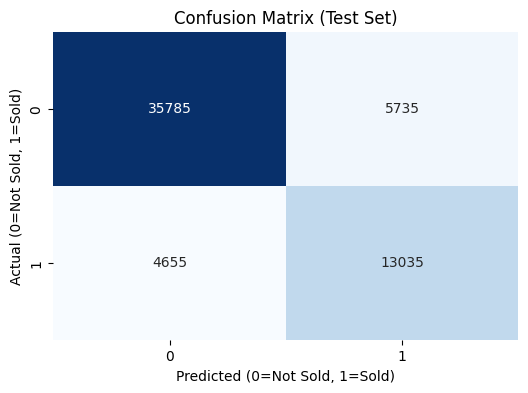

In [ ]:
print(f" Τελική Δοκιμή στο Test Set με: {type(best_clf_model).__name__}")

# 1. Προετοιμασία Test Data
X_test_c, y_test_c = get_X_y(test_clf, clf_features, 'QuantitySold')

# 2. Scaling (Μόνο αν κέρδισε η Logistic Regression)
if use_scaler_for_test:
    X_test_final = scaler_c.transform(X_test_c)
else:
    X_test_final = X_test_c

# 3. Πρόβλεψη
final_preds_c = best_clf_model.predict(X_test_final)

# 4. Αναλυτικά Αποτελέσματα
print("\n Classification Report:")
print(classification_report(y_test_c, final_preds_c))

print("-" * 30)
acc_final = accuracy_score(y_test_c, final_preds_c)
print(f" Final Test Accuracy: {acc_final:.4f}")

# AUC Score (Πόσο καλά ξεχωρίζει τις κλάσεις)
try:
    # Προσπαθούμε να πάρουμε πιθανότητες για πιο ακριβές AUC
    probs = best_clf_model.predict_proba(X_test_final)[:, 1]
    auc = roc_auc_score(y_test_c, probs)
    print(f" ROC-AUC Score:      {auc:.4f}")
except:
    print("ROC-AUC requires probability prediction.")

# 5. Confusion Matrix (Οπτικοποίηση)
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test_c, final_preds_c)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted (0=Not Sold, 1=Sold)')
plt.ylabel('Actual (0=Not Sold, 1=Sold)')
plt.show()

## 8. Στόχος Γ: Πρόβλεψη Ανταγωνιστικότητας (Binary Classification)

Σύμφωνα με την εκφώνηση, δημιουργούμε ένα νέο πρόβλημα κατηγοριοποίησης στο υποσύνολο των πωληθέντων αντικειμένων (`Full_subset`).
Ορίζουμε τη μεταβλητή στόχο **`IsHighPrice`**:
* **1 (High Price):** Αν `Price` >= `AvgPrice` (Πάνω από τον μέσο όρο).
* **0 (Low Price):** Αν `Price` < `AvgPrice` (Κάτω από τον μέσο όρο).

**Διαχείριση Ανισορροπίας:**
Η κατανομή των κλάσεων είναι περίπου **70% (Low) - 30% (High)**.
Για να αντιμετωπίσουμε αυτή την ανισορροπία χωρίς να αλλοιώσουμε τα δεδομένα (όπως θα έκανε το SMOTE), χρησιμοποιούμε την παράμετρο **`class_weight='balanced'`**. Αυτό αναγκάζει τα μοντέλα να δώσουν μεγαλύτερη βαρύτητα στα δείγματα της μειοψηφούσας κλάσης.

**Προσοχή στο Data Leakage:**
Από τα χαρακτηριστικά εισόδου αφαιρούμε αυστηρά το `Price` και το `AvgPrice`, καθώς αυτά χρησιμοποιούνται για τον υπολογισμό του στόχου.

In [ ]:
print("--- ΕΚΚΙΝΗΣΗ ΣΤΟΧΟΥ Γ: Price vs AvgPrice ---")

# 1. Δημιουργία του Στόχου (Target Construction)
# Συνάρτηση που φτιάχνει το y (1 αν Price >= AvgPrice, αλλιώς 0)
def create_target_gamma(df):
    # ΠΡΟΣΟΧΗ: Συγκρίνουμε τις στήλες του DataFrame
    return (df['Price'] >= df['AvgPrice']).astype(int)

# Δημιουργούμε τα y για τα 3 σύνολα (από τα _reg dataframes που έχουν μόνο τα πωληθέντα)
y_train_g = create_target_gamma(train_reg)
y_val_g   = create_target_gamma(val_reg)
y_test_g  = create_target_gamma(test_reg)

print("Κατανομή Στόχου (Train):")
print(y_train_g.value_counts(normalize=True).mul(100).round(2))

# 2. Επιλογή Features
# Χρησιμοποιούμε τα features του Regression, αλλά αφαιρούμε οτιδήποτε σχετικό με Price/AvgPrice
features_gamma = features.copy()

# Λίστα απαγορευμένων (για σιγουριά)
forbidden = ['Price', 'AvgPrice', 'SellerAvg', 'AuctionMedianPrice', 'PricePercent']
features_gamma = [f for f in features_gamma if f not in forbidden]

print(f"\nFeatures ({len(features_gamma)}): {features_gamma}")

# 3. Προετοιμασία X
X_train_g, _ = get_X_y(train_reg, features_gamma, 'Price') # Το target εδώ είναι dummy, έχουμε το y_train_g
X_val_g, _   = get_X_y(val_reg, features_gamma, 'Price')

# 4. Scaling (Για Logistic Regression)
scaler_g = StandardScaler()
X_train_g_sc = scaler_g.fit_transform(X_train_g)
X_val_g_sc   = scaler_g.transform(X_val_g)

# 5. Εκπαίδευση & Σύγκριση (με class_weight='balanced')

# --- Logistic Regression ---
print("\n1. Logistic Regression (balanced)...")
lr_g = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_g.fit(X_train_g_sc, y_train_g)

preds_lr = lr_g.predict(X_val_g_sc)
acc_lr = accuracy_score(y_val_g, preds_lr)
print(f"   Validation Accuracy: {acc_lr:.4f}")
print("   Classification Report (LogReg):")
print(classification_report(y_val_g, preds_lr))

# --- Random Forest ---
print("\n2. Random Forest (balanced)...")
rf_g = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=4, class_weight='balanced', random_state=42, n_jobs=-1)
rf_g.fit(X_train_g, y_train_g)

preds_rf = rf_g.predict(X_val_g)
acc_rf = accuracy_score(y_val_g, preds_rf)
print(f"   Validation Accuracy: {acc_rf:.4f}")
print("   Classification Report (Random Forest):")
print(classification_report(y_val_g, preds_rf))

# Επιλογή Νικητή
if acc_rf > acc_lr:
    print(f"\nΝικητής: Random Forest (Acc: {acc_rf:.4f})")
    best_gamma_model = rf_g
    use_scaler_gamma = False
else:
    print(f"\nΝικητής: Logistic Regression (Acc: {acc_lr:.4f})")
    best_gamma_model = lr_g
    use_scaler_gamma = True

--- ΕΚΚΙΝΗΣΗ ΣΤΟΧΟΥ Γ: Price vs AvgPrice ---
Κατανομή Στόχου (Train):
0    69.54
1    30.46
Name: proportion, dtype: float64

Features (7): ['Category', 'StartingBid', 'Authenticated', 'ReturnsAccepted', 'IsHOF', 'Seller_Avg_Price', 'Day_Avg_Price']

1. Logistic Regression (balanced)...
   Validation Accuracy: 0.6503
   Classification Report (LogReg):
              precision    recall  f1-score   support

           0       0.76      0.72      0.74     12237
           1       0.45      0.51      0.48      5588

    accuracy                           0.65     17825
   macro avg       0.60      0.61      0.61     17825
weighted avg       0.66      0.65      0.66     17825


2. Random Forest (balanced)...
   Validation Accuracy: 0.7067
   Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       0.82      0.74      0.78     12237
           1       0.53      0.64      0.58      5588

    accuracy                           0.71     17

## 8.1 Τελική Αξιολόγηση Ανταγωνιστικότητας (Test Set)

Εφαρμόζουμε το **Random Forest** (το οποίο επιλέχθηκε ως το βέλτιστο μοντέλο) στο "κρυφό" Test Set (`test_reg`).
Εστιάζουμε στο κατά πόσο το μοντέλο μπορεί να εντοπίσει την κλάση **1 (High Price)**, που είναι και ο επιχειρηματικός στόχος (να βρούμε ποιες δημοπρασίες θα αποφέρουν κέρδος).

--- Τελική Δοκιμή (Goal C) με Random Forest ---

 Final Test Accuracy: 0.7079
 Baseline Accuracy:   0.6965 (τυχαία επιλογή 'Low')

 Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.74      0.78     12415
           1       0.52      0.63      0.57      5410

    accuracy                           0.71     17825
   macro avg       0.67      0.69      0.67     17825
weighted avg       0.73      0.71      0.72     17825



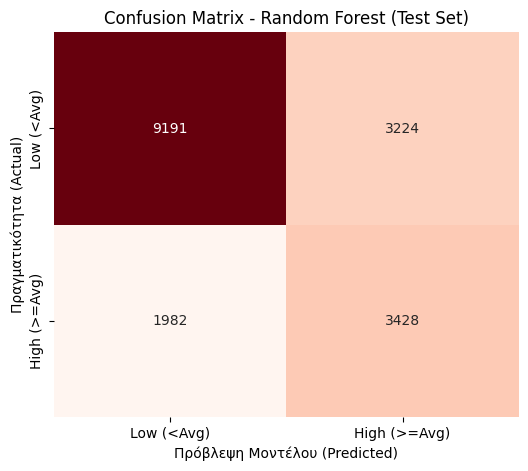

In [ ]:
print(f"--- Τελική Δοκιμή (Goal C) με Random Forest ---")

# 1. Προετοιμασία Test Set (για τον Στόχο Γ)
# Χρησιμοποιούμε τα features_gamma (που ΔΕΝ έχουν Price/AvgPrice)
X_test_g, _ = get_X_y(test_reg, features_gamma, 'Price')

# Φτιάχνουμε τον στόχο y για το Test Set
y_test_gamma = create_target_gamma(test_reg)

# 2. Πρόβλεψη (Δεν χρειάζεται scaler το Random Forest)
final_preds_g = best_gamma_model.predict(X_test_g)

# 3. Μετρικές
final_acc_g = accuracy_score(y_test_gamma, final_preds_g)
print(f"\n Final Test Accuracy: {final_acc_g:.4f}")
print(f" Baseline Accuracy:   {1 - y_test_gamma.mean():.4f} (τυχαία επιλογή 'Low')")

print("\n Classification Report:")
print(classification_report(y_test_gamma, final_preds_g))

# 4. Confusion Matrix
plt.figure(figsize=(6, 5))
cm_g = confusion_matrix(y_test_gamma, final_preds_g)
sns.heatmap(cm_g, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Low (<Avg)', 'High (>=Avg)'],
            yticklabels=['Low (<Avg)', 'High (>=Avg)'])
plt.xlabel('Πρόβλεψη Μοντέλου (Predicted)')
plt.ylabel('Πραγματικότητα (Actual)')
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.show()

## 9. Ερμηνεία Μοντέλων & Σημαντικότητα Χαρακτηριστικών (Feature Importance)

Πέρα από την ακρίβεια των προβλέψεων, είναι κρίσιμο να κατανοήσουμε **ποιες μεταβλητές επηρεάζουν περισσότερο** το αποτέλεσμα των δημοπρασιών. Αυτό μας δίνει εικόνα για τη συμπεριφορά της αγοράς.

Θα εφαρμόσουμε δύο διαφορετικές τεχνικές ερμηνείας, ανάλογα με τη φύση του μοντέλου:

### 1. Classification (Random Forest): Gini Importance
Τα δενδρικά μοντέλα (όπως το Random Forest) παρέχουν εγγενώς (natively) τη σημαντικότητα των χαρακτηριστικών. Υπολογίζεται με βάση το πόσο κάθε μεταβλητή βοηθάει στη μείωση της "ακαθαρσίας" (impurity) κατά τον διαχωρισμό των κόμβων στα δέντρα.
* **Στόχος:** Να δούμε ποιοι παράγοντες καθορίζουν αν μια δημοπρασία θα είναι **Ανταγωνιστική (Πώληση)** ή όχι.

### 2. Regression (k-NN): Permutation Importance
Ο αλγόριθμος k-NN δεν έχει βάρη (weights) ή συντελεστές, καθώς βασίζεται σε αποστάσεις. Γι' αυτό, για να βρούμε τη σημαντικότητα, χρησιμοποιούμε την τεχνική **Permutation Importance**.
* **Πώς λειτουργεί:** Ανακατεύουμε τυχαία (shuffle) τις τιμές μιας στήλης (π.χ. `SellerRating`) και μετράμε πόσο χαλάει (αυξάνεται) το σφάλμα του μοντέλου.
* **Λογική:** Αν ανακατέψουμε μια στήλη και το μοντέλο "καταστραφεί", τότε η στήλη ήταν πολύ σημαντική. Αν το σφάλμα μείνει ίδιο, η στήλη ήταν αδιάφορη.
* **Στόχος:** Να δούμε ποιοι παράγοντες επηρεάζουν το ύψος της **Τελικής Τιμής**.

 1. Σημαντικότητα Χαρακτηριστικών για Classification (Random Forest)


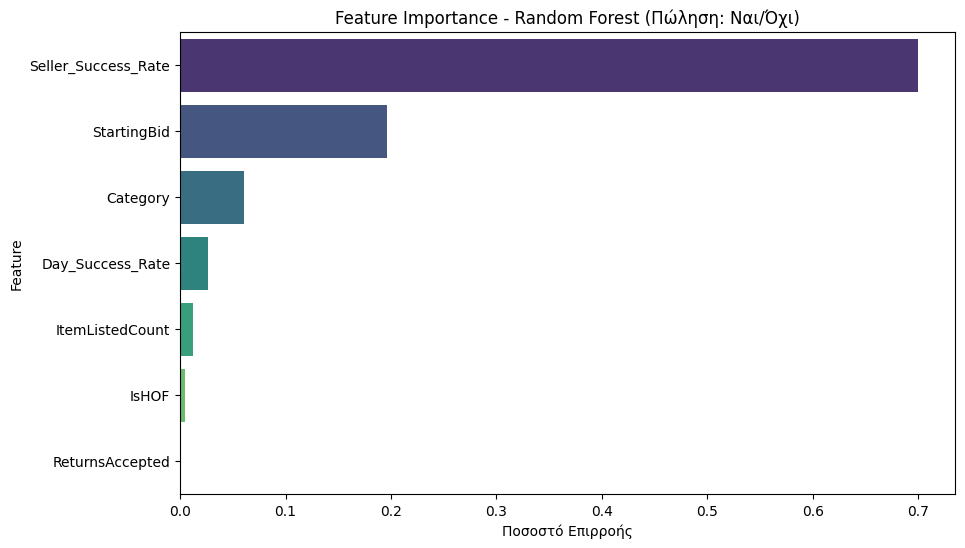


 2. Σημαντικότητα Χαρακτηριστικών για Regression (k-NN)
 Επαναδημιουργία του k-NN για ανάλυση...
 Υπολογισμός Permutation Importance... (Περιμένετε λίγο)


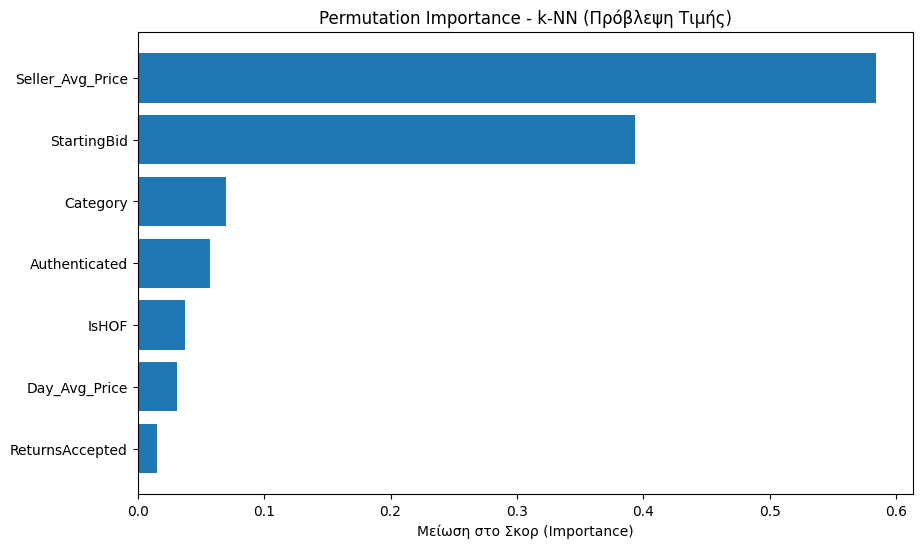

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.neighbors import KNeighborsRegressor
# ---------------------------------------------------------
# 1. Feature Importance για το Random Forest (Classification)
# ---------------------------------------------------------
print(" 1. Σημαντικότητα Χαρακτηριστικών για Classification (Random Forest)")

if 'best_clf_model' in locals():
    # Παίρνουμε τις τιμές σημαντικότητας
    importances = best_clf_model.feature_importances_

    # Δημιουργούμε DataFrame
    feature_imp_df = pd.DataFrame({
        'Feature': clf_features,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    # Γράφημα
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
    plt.title('Feature Importance - Random Forest (Πώληση: Ναι/Όχι)')
    plt.xlabel('Ποσοστό Επιρροής')
    plt.show()
else:
    print(" Το μοντέλο Random Forest (best_clf_model) δεν βρέθηκε στη μνήμη.")


# ---------------------------------------------------------
# 2. Permutation Importance για το k-NN (Regression)
# ---------------------------------------------------------
print("\n 2. Σημαντικότητα Χαρακτηριστικών για Regression (k-NN)")

# Επαναφέρουμε το μοντέλο k-NN με τις βέλτιστες παραμέτρους για σιγουριά
# (ώστε να μην χτυπήσει NameError)
if 'knn_final' in locals():
    model_to_explain = knn_final
else:
    print(" Επαναδημιουργία του k-NN για ανάλυση...")
    model_to_explain = KNeighborsRegressor(n_neighbors=30, weights='distance', metric='manhattan', n_jobs=-1)
    model_to_explain.fit(X_train_sc, y_train)

print(" Υπολογισμός Permutation Importance... (Περιμένετε λίγο)")

# Υπολογισμός
perm_importance = permutation_importance(model_to_explain, X_test_sc, y_test, n_repeats=10, random_state=42)

# Ταξινόμηση
sorted_idx = perm_importance.importances_mean.argsort()

# Γράφημα
plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_idx)), perm_importance.importances_mean[sorted_idx], align='center')
plt.yticks(range(len(sorted_idx)), [features[i] for i in sorted_idx])
plt.xlabel("Μείωση στο Σκορ (Importance)")
plt.title("Permutation Importance - k-NN (Πρόβλεψη Τιμής)")
plt.show()

# 10. Βελτιστοποίηση Μοντέλων (Hyperparameter Tuning)

Σε αυτό το στάδιο θα χρησιμοποιήσουμε τη μέθοδο Grid Search για να βρούμε τις βέλτιστες παραμέτρους για τα μοντέλα μας, με στόχο τη μεγιστοποίηση της απόδοσης.

## 10.1. Grid Search για Random Forest (Classification)
Δοκιμάζουμε διαφορετικούς συνδυασμούς για το πλήθος των δέντρων (n_estimators), το μέγιστο βάθος (max_depth) και τα ελάχιστα δείγματα ανά φύλλο (min_samples_leaf).

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

print("--- Εναρξη Grid Search για Random Forest (Classification) ---")

# Ορισμός παραμέτρων που θα δοκιμάσουμε
param_grid_rf = {
    'n_estimators': [100, 200],        # Πλήθος δέντρων
    'max_depth': [10, 20, None],       # Μέγιστο βάθος
    'min_samples_leaf': [1, 2, 4],     # Ελάχιστα δείγματα στο φύλλο
    'bootstrap': [True]
}

# Ρύθμιση του Grid Search
# n_jobs=-1: Χρησιμοποιεί όλους τους πυρήνες
grid_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42),
                       param_grid=param_grid_rf,
                       cv=5,            # 5-fold Cross Validation
                       n_jobs=-1,
                       verbose=2,
                       scoring='accuracy')

# Εκπαίδευση
# Χρησιμοποιούμε το X_train_c και το y_train_c για classification
grid_rf.fit(X_train_c, y_train_c)

# Αποτελέσματα
print(f"\n Βέλτιστες Παράμετροι RF: {grid_rf.best_params_}")
print(f" Καλύτερη Ακρίβεια (CV Score): {grid_rf.best_score_:.2%}")

# Τελική Αξιολόγηση στο Test Set
best_rf_model = grid_rf.best_estimator_
y_pred_rf_opt = best_rf_model.predict(X_test_c) # Use X_test_c for classification test data

print("\n--- Classification Report (Βελτιστοποιημένο RF) ---")
print(classification_report(y_test_c, y_pred_rf_opt)) # Use y_test_c for classification test target

--- Εναρξη Grid Search για Random Forest (Classification) ---
Fitting 5 folds for each of 18 candidates, totalling 90 fits

 Βέλτιστες Παράμετροι RF: {'bootstrap': True, 'max_depth': 20, 'min_samples_leaf': 4, 'n_estimators': 100}
 Καλύτερη Ακρίβεια (CV Score): 86.18%

--- Classification Report (Βελτιστοποιημένο RF) ---
              precision    recall  f1-score   support

           0       0.85      0.93      0.89     41520
           1       0.80      0.62      0.70     17690

    accuracy                           0.84     59210
   macro avg       0.83      0.78      0.79     59210
weighted avg       0.84      0.84      0.83     59210



## 10.2. Grid Search για k-NN (Regression)
Για το πρόβλημα παλινδρόμησης, βελτιστοποιούμε τον αλγόριθμο k-NN αναζητώντας τον ιδανικό αριθμό γειτόνων (k), τον τρόπο στάθμισης (weights) και τη μετρική απόστασης (metric).

In [ ]:
from sklearn.model_selection import GridSearchCV # <--- Χρειαζόταν αυτό
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n--- Εναρξη Grid Search για k-NN (Regression) ---")

# Παράμετροι για δοκιμή
param_grid_knn = {
    'n_neighbors': [10, 20, 30, 40 , 50 ],      # Αριθμός γειτόνων
    'weights': ['uniform', 'distance'],  # Βάρη (ίσα ή βάσει απόστασης)
    'metric': ['euclidean', 'manhattan'] # Μετρική απόστασης
}

# Grid Search
grid_knn = GridSearchCV(estimator=KNeighborsRegressor(),
                        param_grid=param_grid_knn,
                        cv=5,
                        n_jobs=-1,
                        verbose=1,
                        scoring='neg_root_mean_squared_error')

# Έλεγχος αν υπάρχουν scaled δεδομένα
if 'X_train_sc' in locals():
    X_for_knn = X_train_sc
    X_test_for_knn = X_test_sc
else:
    print(" Προσοχή: Δεν βρέθηκε Scaled dataset. Χρησιμοποιώ το απλό X_train.")
    X_for_knn = X_train
    X_test_for_knn = X_test

# Εκπαίδευση (Χρησιμοποιούμε το y_train_log)
grid_knn.fit(X_for_knn, y_train_log)

# Αποτελέσματα
print(f"\n Βέλτιστες Παράμετροι k-NN: {grid_knn.best_params_}")
best_knn_rmse_log = -grid_knn.best_score_
print(f" Καλύτερο RMSE (CV Score - Log scale): {best_knn_rmse_log:.4f}")

# --- Η ΔΙΟΡΘΩΣΗ ΕΙΝΑΙ ΕΔΩ ---
# Πρέπει να πάρουμε το νικητήριο μοντέλο από το grid_knn
best_knn_model = grid_knn.best_estimator_

# Πρόβλεψη (σε Log κλίμακα)
pred_knn_log = best_knn_model.predict(X_test_for_knn)

# Αντιστροφή σε πραγματικές τιμές (Real Price)
pred_knn_real = np.expm1(pred_knn_log)

# Τελικό σφάλμα (Real vs Real)
final_rmse = np.sqrt(mean_squared_error(y_test, pred_knn_real))

print(f" Τελικό RMSE στο Test Set: {final_rmse:.4f}")


--- Εναρξη Grid Search για k-NN (Regression) ---
Fitting 5 folds for each of 20 candidates, totalling 100 fits

 Βέλτιστες Παράμετροι k-NN: {'metric': 'euclidean', 'n_neighbors': 50, 'weights': 'distance'}
 Καλύτερο RMSE (CV Score - Log scale): 0.5686
 Τελικό RMSE στο Test Set: 29.3860
